
# CEvNS-pyEFT — CsI Flavor Slow-chain diagnostic

目标：在接 SNuDD 之前，先验证当前 `flavor-refactor-source-state-v4` 本地工作树中的
**COHERENT CsI2017 / CsI2021 Slow 链是否能实际运行**。

当前物理合同：

\[
C[\mathrm{final},\mathrm{initial}],\qquad
K=C^\dagger C,\qquad
\frac{d\sigma}{dE_R}=\mathrm{Tr}(\rho K).
\]

根据 2026-09-02 当前状态：
- P0–P2 已通过；
- `NeutrinoState` 已支持常量和能量依赖 \(\rho\)；
- CsI Phase 0–6 已通过；
- Phase 7 的 source-state 接线已写；
- **Gate L 尚未正式通过**。

所以这份 notebook 是 **CsI 可执行性 + Slow 链 smoke test**，不是提前宣称 Gate L PASS。

> 注意：`particle_kind="antinu"` 当前只严格保存粒子标签；
> 反中微子的 vector/axial、parity-odd、LNC/LNV 符号仍需独立审计。


In [1]:

from pathlib import Path
import sys, inspect, subprocess
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for root in [here, *here.parents]:
        if (root / "src" / "cevns_pyeft").is_dir():
            return root
    raise FileNotFoundError(
        "找不到 src/cevns_pyeft。请把 notebook 放进当前 Gitup01 后运行。"
    )

ROOT = find_repo_root()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

RESPONSES = ROOT / "data" / "responses" / "responses_all.json"

print("ROOT      =", ROOT)
print("RESPONSES =", RESPONSES)
assert RESPONSES.exists(), f"Missing: {RESPONSES}"


ROOT      = F:\Work\2026-07-15 CEvNSpyEFT-Local\260820Gitup1-Flavor\git-worktree-f0\Gitup01
RESPONSES = F:\Work\2026-07-15 CEvNSpyEFT-Local\260820Gitup1-Flavor\git-worktree-f0\Gitup01\data\responses\responses_all.json



## 1. 导入当前 source-state 与 CsI Slow API


In [2]:

from cevns_pyeft.experiments.coherent.sns import sns_component_state
from cevns_pyeft.experiments.coherent.slow_counts_csi2017 import slow_counts_csi2017
from cevns_pyeft.experiments.coherent.slow_counts_csi2021 import slow_counts_csi2021

print("sns_component_state :", inspect.signature(sns_component_state))
print("slow_counts_csi2017 :", inspect.signature(slow_counts_csi2017))
print("slow_counts_csi2021 :", inspect.signature(slow_counts_csi2021))


sns_component_state : (component: 'SourceSpecies') -> 'NeutrinoState'
slow_counts_csi2017 : (responses_json: 'str | Path', wc_triplets: 'Optional[Mapping[Triplet, complex]]' = None, *, include_sm: 'bool' = True, sin2thetaW: 'float' = 0.2387, c10_mass_mode: 'str' = 'flavor', n_er: 'int' = 21, n_enu: 'int' = 120, n_pe_bin: 'int' = 8, pe_step: 'float' = 3.0, efficiency_data_path: 'str | Path' = 'data/datafiles/COHERENT_eff.txt') -> 'Dict[str, Any]'
slow_counts_csi2021 : (responses_json: 'str | Path', wc_triplets: 'Optional[Mapping[Triplet, complex]]' = None, *, include_sm: 'bool' = True, sin2thetaW: 'float' = 0.2387, c10_mass_mode: 'str' = 'flavor', n_er: 'int' = 21, n_enu: 'int' = 120, n_pe_bin: 'int' = 8, pe_step: 'float' = 3.0) -> 'Dict[str, Any]'



## 2. 检查 SNS 三个物理分量

应该满足：

\[
\nu_\mu^{\rm prompt}\to(\nu,\rho_\mu),\quad
\nu_e^{\rm delayed}\to(\nu,\rho_e),\quad
\bar\nu_\mu^{\rm delayed}\to(\bar\nu,\rho_\mu).
\]


In [3]:

component_candidates = {
    "prompt_nu_mu": ["mu", "nu_mu", "prompt_nu_mu"],
    "delayed_nu_e": ["e", "nu_e", "delayed_nu_e"],
    "delayed_antinu_mu": ["mub", "antinu_mu", "delayed_antinu_mu"],
}

states = {}

for physical_name, candidates in component_candidates.items():
    last_error = None
    for label in candidates:
        try:
            state = sns_component_state(label)
            states[physical_name] = (label, state)
            break
        except Exception as exc:
            last_error = exc
    else:
        raise RuntimeError(
            f"{physical_name} 无法由 {candidates} 构造。最后错误: {last_error}"
        )

for physical_name, (label, state) in states.items():
    print("\n", physical_name, "label =", repr(label))
    print("type          =", type(state))
    print("particle_kind =", getattr(state, "particle_kind", "<missing>"))
    print("object        =", state)



 prompt_nu_mu label = 'mu'
type          = <class 'cevns_pyeft.sources.state.NeutrinoState'>
particle_kind = nu
object        = NeutrinoState(particle_kind='nu', rho=array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j]]))

 delayed_nu_e label = 'e'
type          = <class 'cevns_pyeft.sources.state.NeutrinoState'>
particle_kind = nu
object        = NeutrinoState(particle_kind='nu', rho=array([[1.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j]]))

 delayed_antinu_mu label = 'mub'
type          = <class 'cevns_pyeft.sources.state.NeutrinoState'>
particle_kind = antinu
object        = NeutrinoState(particle_kind='antinu', rho=array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j]]))



## 3. 运行 P2 source-state 测试

当前状态文档记录的是 `7 passed`。这里重新在你的实际工作树中运行。


In [4]:

test_file = ROOT / "tests" / "test_source_state_p2.py"

if test_file.exists():
    p = subprocess.run(
        [sys.executable, "-m", "pytest", str(test_file), "-q"],
        cwd=ROOT, text=True, capture_output=True
    )
    print(p.stdout)
    if p.stderr:
        print(p.stderr)
    assert p.returncode == 0, "P2 source-state tests failed"
else:
    print("没有找到 tests/test_source_state_p2.py，跳过。")


.......                                                                  [100%]
============================== warnings summary ===============================
..\..\..\..\.codex_conda_envs\codex-py311\Lib\site-packages\_pytest\cacheprovider.py:469
  f:\Work\.codex_conda_envs\codex-py311\Lib\site-packages\_pytest\cacheprovider.py:469: PytestCacheWarning: could not create cache path F:\Work\2026-07-15 CEvNSpyEFT-Local\260820Gitup1-Flavor\git-worktree-f0\Gitup01\.pytest_cache\v\cache\nodeids: [WinError 5] 拒绝访问。: 'F:\\Work\\2026-07-15 CEvNSpyEFT-Local\\260820Gitup1-Flavor\\git-worktree-f0\\Gitup01\\.pytest_cache\\v\\cache'
    config.cache.set("cache/nodeids", sorted(self.cached_nodeids))

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
7 passed, 1 warning in 0.59s




## 4. CsI2017 — SM Slow 小网格

只打开 SM：

```python
wc_triplets = {}
include_sm = True
```

目的只是先验证整条

\[
\text{SNS state}\to d\sigma/dE_R\to \text{flux folding}
\to \text{Cs/I}\to \text{detector response}\to \text{PE bins}
\]

能够跑通。

这个网格只是 smoke test，不是最终 Gate-L frozen grid。


In [5]:

sig2017 = inspect.signature(slow_counts_csi2017)

kwargs2017 = {
    "wc_triplets": {},
    "include_sm": True,
}

for name, value in {"n_er": 32, "n_enu": 48}.items():
    if name in sig2017.parameters:
        kwargs2017[name] = value

print("kwargs =", kwargs2017)

res2017 = slow_counts_csi2017(
    RESPONSES,
    **kwargs2017,
)

print("type =", type(res2017))
if isinstance(res2017, dict):
    print("keys =", list(res2017.keys()))


kwargs = {'wc_triplets': {}, 'include_sm': True, 'n_er': 32, 'n_enu': 48}
type = <class 'dict'>
keys = ['counts_per_bin', 'counts_per_npe', 'target_flavor_dndpe_grid', 'pe_grid', 'pe_bins', 'dataset']


In [6]:

def extract_1d_spectra(result):
    out = {}
    if not isinstance(result, dict):
        return out

    containers = []
    cpb = result.get("counts_per_bin")
    if isinstance(cpb, dict):
        containers.append(("counts_per_bin", cpb))
    containers.append(("top", result))

    for prefix, container in containers:
        for key, value in container.items():
            try:
                arr = np.asarray(value, dtype=float)
            except Exception:
                continue
            if arr.ndim == 1 and arr.size > 0:
                out[f"{prefix}:{key}"] = arr
    return out

spec2017 = extract_1d_spectra(res2017)

for key, arr in spec2017.items():
    print(
        f"{key:30s} shape={arr.shape} "
        f"sum={arr.sum():.8g} min={arr.min():.5g} max={arr.max():.5g}"
    )

total2017 = spec2017.get("counts_per_bin:total", spec2017.get("top:total"))
assert total2017 is not None, "找不到 CsI2017 total spectrum"
assert np.all(np.isfinite(total2017))
assert np.min(total2017) >= -1e-10

print("\nCsI2017 smoke-grid total =", float(total2017.sum()))


counts_per_bin:mu              shape=(25,) sum=27.26166 min=0 max=6.9961
counts_per_bin:e               shape=(25,) sum=57.409368 min=6.3177e-09 max=8.4593
counts_per_bin:mub             shape=(25,) sum=88.610587 min=6.8616e-09 max=11.743
counts_per_bin:total           shape=(25,) sum=173.28162 min=2.0011e-08 max=26.261
top:pe_grid                    shape=(251,) sum=6275.1255 min=0.001 max=50
top:pe_bins                    shape=(26,) sum=650.013 min=0.001 max=50

CsI2017 smoke-grid total = 173.28161525792385


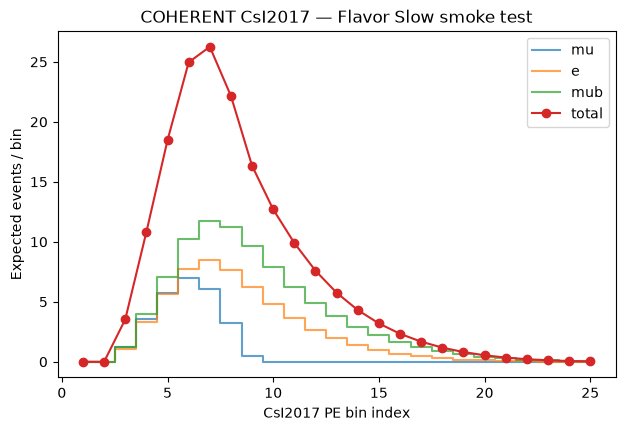

In [7]:

fig, ax = plt.subplots(figsize=(7.2, 4.5))
x = np.arange(1, len(total2017) + 1)

for key, arr in spec2017.items():
    if key.endswith(":total"):
        continue
    if arr.shape == total2017.shape:
        ax.step(x, arr, where="mid", alpha=0.7, label=key.split(":",1)[1])

ax.plot(x, total2017, marker="o", label="total")
ax.set_xlabel("CsI2017 PE bin index")
ax.set_ylabel("Expected events / bin")
ax.set_title("COHERENT CsI2017 — Flavor Slow smoke test")
ax.legend()
plt.show()



## 5. CsI2021 — SM Slow 小网格

CsI2021 必须走自己的 quenching → PE smearing → logistic efficiency 链，
不能用 CsI2017 的 \(1.17\ {\rm PE/keV}\) 线性近似代替。


In [8]:

sig2021 = inspect.signature(slow_counts_csi2021)

kwargs2021 = {
    "wc_triplets": {},
    "include_sm": True,
}

for name, value in {"n_er": 32, "n_enu": 48, "n_pe_bin": 24}.items():
    if name in sig2021.parameters:
        kwargs2021[name] = value

print("kwargs =", kwargs2021)

res2021 = slow_counts_csi2021(
    RESPONSES,
    **kwargs2021,
)

print("type =", type(res2021))
if isinstance(res2021, dict):
    print("keys =", list(res2021.keys()))


kwargs = {'wc_triplets': {}, 'include_sm': True, 'n_er': 32, 'n_enu': 48, 'n_pe_bin': 24}
type = <class 'dict'>
keys = ['counts_per_bin', 'counts_per_npe', 'target_flavor_counts_per_bin', 'pe_bins', 'model_note']


In [9]:

spec2021 = extract_1d_spectra(res2021)

for key, arr in spec2021.items():
    print(
        f"{key:30s} shape={arr.shape} "
        f"sum={arr.sum():.8g} min={arr.min():.5g} max={arr.max():.5g}"
    )

total2021 = spec2021.get("counts_per_bin:total", spec2021.get("top:total"))
assert total2021 is not None, "找不到 CsI2021 total spectrum"
assert np.all(np.isfinite(total2021))
assert np.min(total2021) >= -1e-10

print("\nCsI2021 smoke-grid total =", float(total2021.sum()))


counts_per_bin:mu              shape=(9,) sum=52.011453 min=2.1062e-05 max=19.091
counts_per_bin:e               shape=(9,) sum=107.72119 min=0.72874 max=23.797
counts_per_bin:mub             shape=(9,) sum=171.85526 min=0.89878 max=33.047
counts_per_bin:total           shape=(9,) sum=331.5879 min=2.5006 max=75.935
top:pe_bins                    shape=(10,) sum=260.01 min=0.001 max=60.001

CsI2021 smoke-grid total = 331.58789920920714


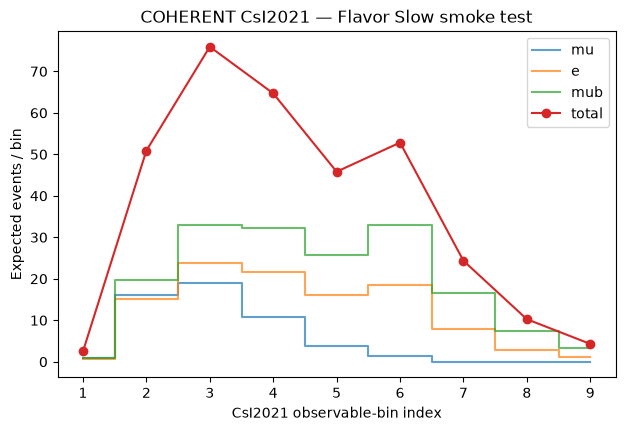

In [10]:

fig, ax = plt.subplots(figsize=(7.2, 4.5))
x = np.arange(1, len(total2021) + 1)

for key, arr in spec2021.items():
    if key.endswith(":total"):
        continue
    if arr.shape == total2021.shape:
        ax.step(x, arr, where="mid", alpha=0.7, label=key.split(":",1)[1])

ax.plot(x, total2021, marker="o", label="total")
ax.set_xlabel("CsI2021 observable-bin index")
ax.set_ylabel("Expected events / bin")
ax.set_title("COHERENT CsI2021 — Flavor Slow smoke test")
ax.legend()
plt.show()



## 6. 如何解释结果

如果 notebook 从头到尾无错误：

- P2 source state 仍然有效；
- SNS 三个分量能够构造成 `NeutrinoState`；
- CsI2017 Slow 可以运行；
- CsI2021 Slow 可以运行；
- detector response 后得到有限、非负的 binned counts。

这可以说明 **“CsI 已经能够处理”**，但仍然只到 *executable smoke-test*。

正式 Gate L 还必须补：

1. frozen Slow 小网格；
2. prompt / delayed 三分量逐分量报告；
3. 独立的 `Tr(rho K)` reference loop；
4. 旧 scalar benchmark 回归；
5. shape / unit / per-bin 报告；
6. `07_SLOW_COUNTS.md`；
7. YAML `slow_validated: true`。

这些通过后，再进入 Flavor Fast；之后再接正式 SNuDD backend。


In [11]:

summary = {
    "CsI2017_bins": int(total2017.size),
    "CsI2017_total_smoke_grid": float(total2017.sum()),
    "CsI2017_finite": bool(np.all(np.isfinite(total2017))),
    "CsI2021_bins": int(total2021.size),
    "CsI2021_total_smoke_grid": float(total2021.sum()),
    "CsI2021_finite": bool(np.all(np.isfinite(total2021))),
    "status": "EXECUTABLE_SMOKE_TEST_PASS",
    "formal_Gate_L": "NOT_YET_CLAIMED",
}
print(summary)


{'CsI2017_bins': 25, 'CsI2017_total_smoke_grid': 173.28161525792385, 'CsI2017_finite': True, 'CsI2021_bins': 9, 'CsI2021_total_smoke_grid': 331.58789920920714, 'CsI2021_finite': True, 'status': 'EXECUTABLE_SMOKE_TEST_PASS', 'formal_Gate_L': 'NOT_YET_CLAIMED'}


In [12]:
# ============================================================
# CsI2021: reproduce the original CEvNS-pyEFT SM calculation
# ============================================================

import inspect
import numpy as np
import matplotlib.pyplot as plt

from cevns_pyeft.experiments.coherent.slow_counts_csi2021 import (
    slow_counts_csi2021,
)

# Pure SM
wc_triplets = {}
include_sm = True

sig2021 = inspect.signature(slow_counts_csi2021)

# ------------------------------------------------------------
# Use the original CEvNS-pyEFT numerical setup
# instead of the smoke-test grid
# ------------------------------------------------------------
candidate_kwargs = {
    "wc_triplets": wc_triplets,
    "include_sm": include_sm,

    # original/default Slow settings
    "n_er": 21,
    "n_enu": 120,
    "n_pe_bin": 8,
    "pe_step": 3.0,

    # SM weak mixing angle used by the current project baseline
    "sin2thetaW": 0.2387,
}

kwargs2021 = {
    key: value
    for key, value in candidate_kwargs.items()
    if key in sig2021.parameters
}

print("slow_counts_csi2021 signature:")
print(sig2021)

print("\nArguments actually passed:")
print(kwargs2021)

res2021_ref = slow_counts_csi2021(
    RESPONSES,
    **kwargs2021,
)

print("\nReturned keys:")
print(res2021_ref.keys())

if "counts_per_bin" in res2021_ref:
    print("\ncounts_per_bin keys:")
    print(res2021_ref["counts_per_bin"].keys())

if "counts_per_npe" in res2021_ref:
    print("\ncounts_per_npe keys:")
    print(res2021_ref["counts_per_npe"].keys())

slow_counts_csi2021 signature:
(responses_json: 'str | Path', wc_triplets: 'Optional[Mapping[Triplet, complex]]' = None, *, include_sm: 'bool' = True, sin2thetaW: 'float' = 0.2387, c10_mass_mode: 'str' = 'flavor', n_er: 'int' = 21, n_enu: 'int' = 120, n_pe_bin: 'int' = 8, pe_step: 'float' = 3.0) -> 'Dict[str, Any]'

Arguments actually passed:
{'wc_triplets': {}, 'include_sm': True, 'n_er': 21, 'n_enu': 120, 'n_pe_bin': 8, 'pe_step': 3.0, 'sin2thetaW': 0.2387}

Returned keys:
dict_keys(['counts_per_bin', 'counts_per_npe', 'target_flavor_counts_per_bin', 'pe_bins', 'model_note'])

counts_per_bin keys:
dict_keys(['mu', 'e', 'mub', 'total'])

counts_per_npe keys:
dict_keys(['mu', 'e', 'mub', 'total'])


PE centers:
[ 4.001 10.001 14.001 18.001 22.001 28.001 36.001 44.001 54.001]

mu:
[1.25739866e-01 4.01795316e+00 4.77924034e+00 2.70843944e+00
 1.00666721e+00 1.79739505e-01 8.22663983e-03 2.31338336e-04
 2.84835452e-06]

e:
[0.10606197 3.78146902 5.95685971 5.43873624 4.04502265 2.32500834
 0.98330275 0.36632899 0.08830215]

mub:
[0.13143392 4.90753815 8.2608362  8.08293971 6.46391974 4.13577132
 2.06358517 0.92152633 0.2750033 ]

total:
[ 0.36323576 12.70696033 18.99693625 16.23011539 11.5156096   6.64051917
  3.05511456  1.28808666  0.3633083 ]

Raw total number of predicted events =
332.9338350257275


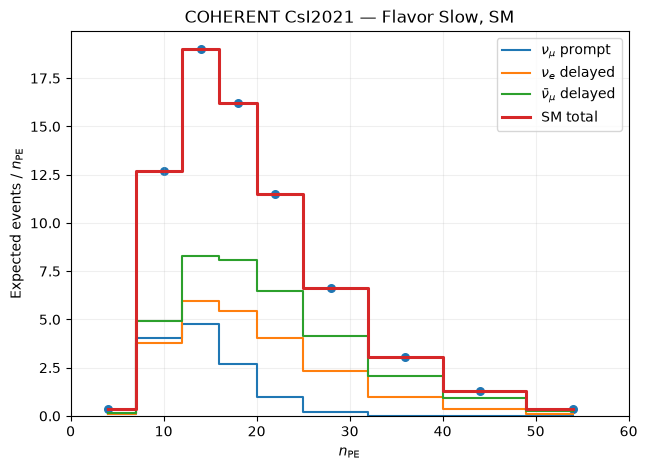

In [13]:
# ============================================================
# Plot the SAME observable used by the original project:
# dN / dn_PE, not raw events / bin
# ============================================================

# Original CsI2021 PE binning
PE_BINS_9 = np.array([
    0.001,
    8.001,
    12.001,
    16.001,
    20.001,
    24.001,
    32.001,
    40.001,
    48.001,
    60.001,
])

PE_WIDTHS_9 = np.diff(PE_BINS_9)

PE_CENTERS_9 = 0.5 * (
    PE_BINS_9[:-1] + PE_BINS_9[1:]
)

# ------------------------------------------------------------
# Prefer the value already returned by the code
# ------------------------------------------------------------
if "counts_per_npe" in res2021_ref:

    counts_npe = res2021_ref["counts_per_npe"]

else:
    # fallback: construct exactly as original code does
    counts_bin = res2021_ref["counts_per_bin"]

    counts_npe = {
        key: np.asarray(value, dtype=float) / PE_WIDTHS_9
        for key, value in counts_bin.items()
    }

mu   = np.asarray(counts_npe["mu"], dtype=float)
e    = np.asarray(counts_npe["e"], dtype=float)
mub  = np.asarray(counts_npe["mub"], dtype=float)
total = np.asarray(counts_npe["total"], dtype=float)

# ------------------------------------------------------------
# Sanity check:
# total must equal the three SNS components
# ------------------------------------------------------------
np.testing.assert_allclose(
    total,
    mu + e + mub,
    rtol=1e-12,
    atol=1e-12,
)

# ------------------------------------------------------------
# Print numerical values
# ------------------------------------------------------------
print("PE centers:")
print(PE_CENTERS_9)

print("\nmu:")
print(mu)

print("\ne:")
print(e)

print("\nmub:")
print(mub)

print("\ntotal:")
print(total)

print("\nRaw total number of predicted events =")
print(
    np.sum(
        res2021_ref["counts_per_bin"]["total"]
    )
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(7.2, 5.0))

ax.step(
    PE_CENTERS_9,
    mu,
    where="mid",
    label=r"$\nu_\mu$ prompt",
)

ax.step(
    PE_CENTERS_9,
    e,
    where="mid",
    label=r"$\nu_e$ delayed",
)

ax.step(
    PE_CENTERS_9,
    mub,
    where="mid",
    label=r"$\bar{\nu}_\mu$ delayed",
)

ax.step(
    PE_CENTERS_9,
    total,
    where="mid",
    linewidth=2.2,
    label="SM total",
)

ax.scatter(
    PE_CENTERS_9,
    total,
    s=30,
)

ax.set_xlabel(r"$n_{\rm PE}$")
ax.set_ylabel(r"Expected events / $n_{\rm PE}$")
ax.set_xlim(0, 60)
ax.set_ylim(bottom=0)

ax.set_title(
    "COHERENT CsI2021 — Flavor Slow, SM"
)

ax.legend()
ax.grid(alpha=0.2)

plt.show()